In [106]:
#kernel used is cannon2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

In [107]:
from astropy.io import ascii as asc
# or
from astropy.table import Table

In [108]:
J0923 = Table.read("/Users/leighharwell2/Desktop/DW/IRchara/lightcurve/J0923+3028.tbl",format="ascii")
#loads in the tables with proper formatting and heading labels
#astropy is able to read in more astro based tables and their formating better that other tools like pandas or numpy

In [109]:
print(J0923)


       mjd         data_collection deep_flg ...  flux_err flux_err_tractor
        d                                   ...    uJy          uJy       
------------------ --------------- -------- ... --------- ----------------
61157.643380251495             qr2    false ... 57.013435        50.053215
   60980.200936039             qr2    false ... 61.317097        51.492626
  61158.1141332955             qr2    false ...  58.37158         52.01662
60980.202428295495             qr2    false ... 62.462505        54.101025
   61158.115625564             qr2    false ... 58.615665         50.08777
   60980.203920564             qr2    false ... 59.590004        51.725243
   61158.117117821             qr2    false ...  58.07874        49.438168
60980.205412809504             qr2    false ... 57.575623         50.14483
   61158.118610078             qr2    false ...  57.63169         49.71038
               ...             ...      ... ...       ...              ...
  61146.6448428675       

In [110]:
print(J0923.colnames)


['mjd', 'data_collection', 'deep_flg', 'det_id', 'flags', 'fit_ql', 'flux_bkg', 'x_image', 'y_image', 'ra', 'dec', 'lvf_id', 'obs_publisher_did', 'lambda', 'lambda_width', 'flux', 'flux_err', 'flux_err_tractor']


In [111]:
#plotting the light curve of the system and constraining it so that we can see the secondary better without too much noise
#need the flux from the systems and observation frame of the light curve
wl = J0923['lambda']
flux = J0923['flux']
flux_err = J0923['flux_err']

In [112]:
#creating a light curve plot
wl = np.array(wl, dtype = float) #μm
f = np.array(flux, dtype = float) #e.g. μJy
f_err = np.array(flux_err, dtype = float) 
t = np.array(J0923['mjd'], dtype = float) #modified julian date


In [113]:
good = np.isfinite(wl) & np.isfinite(f) & np.isfinite(t) #filtering out any non-finite values in the wavelength, flux, and time arrays
#good = np.where((wl > 0.001) & (wl < 25))
# constraining the wavelength range to be between 0.001 and 25 μm or mid-infrared range
t, wl, f = t[good], wl[good], f[good] #applying the filter to the arrays

In [114]:
cmap = plt.cm.turbo   # or "viridis", "rainbow"
norm = Normalize(vmin=np.min(wl), vmax=np.max(wl)) #normalizing the wavelength values for color mapping

In [115]:
#fig, (ax1, ax2) = plt.pyplot.subplots(2, 1, figsize=(10, 8), sharex=True) #creating a figure with two subplots stacked vertically



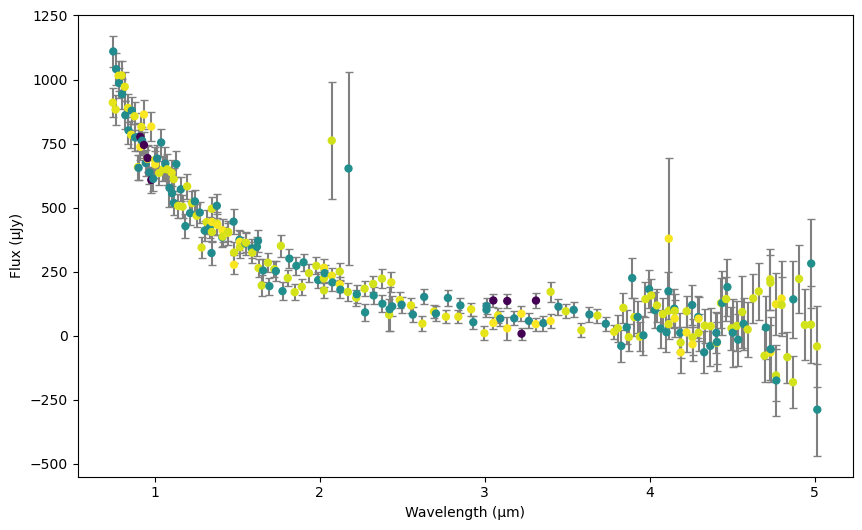

In [116]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.errorbar(wl, f, yerr=f_err, fmt='none', ecolor='gray', capsize=3, zorder=1)

sc = ax.scatter(wl, f, c=t, 
                norm=Normalize(vmin=np.min(t), vmax=np.max(t)),
                s=25, zorder=2)

ax.set_xlabel('Wavelength (μm)')
ax.set_ylabel('Flux (μJy)')

#cbar = fig.colorbar(sc, ax=ax)
#cbar.set_label('MJD')

plt.show()

In [117]:
J0056 = Table.read("/Users/leighharwell2/Desktop/DW/IRchara/lightcurve/J0056-0611.tbl",format="ascii")
#loads in the tables with proper formatting and heading labels
#astropy is able to read in more astro based tables and their formating better that other tools like pandas or numpy

In [118]:
#plotting the light curve of the system and constraining it so that we can see the secondary better without too much noise
#need the flux from the systems and observation frame of the light curve
wl56 = J0056['lambda']
flux56 = J0056['flux']
flux_err56 = J0056['flux_err']


In [119]:
#creating a light curve plot
wl56 = np.array(wl56, dtype = float) #μm
f56 = np.array(flux56, dtype = float) #e.g. μJy
f_err56 = np.array(flux_err56, dtype = float) 
t56 = np.array(J0056['mjd'], dtype = float) #modified julian date


In [120]:
good = (np.isfinite(wl56) & np.isfinite(t56) & np.isfinite(f56)
        & (f56 < 1000) & (f56 > -250)) #filtering out any non-finite values in the wavelength, flux, and time arrays
#good = np.where((wl > 0.001) & (wl < 25))
# constraining the wavelength range to be between 0.001 and 25 μm or mid-infrared range
t56, wl56, f56 = t56[good], wl56[good], f56[good] #applying the filter to the arrays

In [121]:
norm = Normalize(vmin=np.min(wl56), vmax=np.max(wl56)) #normalizing the wavelength values for color mapping

ValueError: 'yerr' (shape: (329,)) must be a scalar or a 1D or (2, n) array-like whose shape matches 'y' (shape: (326,))

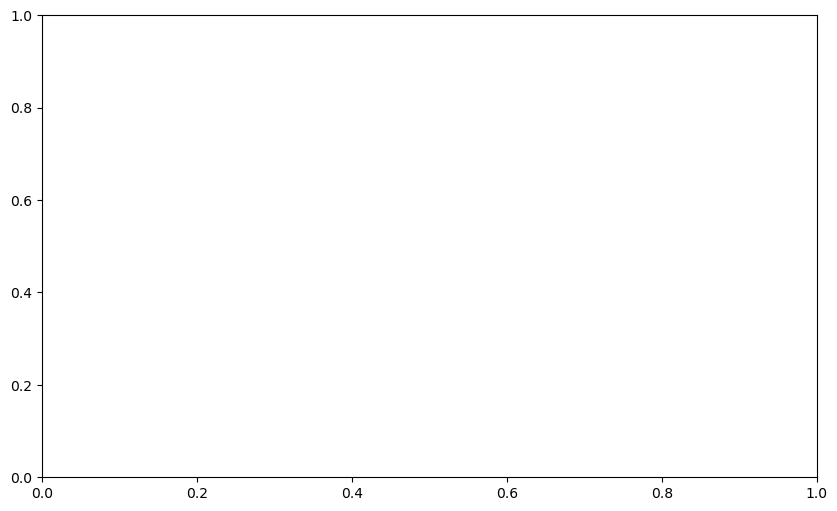

In [122]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.errorbar(wl56, f56, yerr=f_err56, fmt='none', ecolor='gray', capsize=3, zorder=1)

sc = ax.scatter(wl56, f56, c=t, 
                norm=Normalize(vmin=np.min(t56), vmax=np.max(t56)),
                s=25, zorder=2)

ax.set_xlabel('Wavelength (μm)')
ax.set_ylabel('Flux (μJy)')

#cbar = fig.colorbar(sc, ax=ax)
#cbar.set_label('MJD')

plt.show()